In [3]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
from src.cleaning import load_processed
from src.metrics import (add_core_metrics, add_rolling_metrics, add_strain_relief,
                         compute_thresholds, list_flag_windows)

df = add_strain_relief(add_rolling_metrics(add_core_metrics(load_processed())))
rep = df[df["is_reported"]]
print(compute_thresholds(df))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
(np.float64(8281.525), np.float64(2494.34375))


In [4]:
print(list_flag_windows(df, "strain_flag"))
print(list_flag_windows(df, "relief_flag"))

        start         end  reports  calendar_days  avg_total_load
0  2023-03-30  2023-04-10        8             12            8260
1  2023-05-02  2023-05-25       18             24            8598
2  2023-08-08  2024-01-24      112            170           10297
3  2024-01-30  2024-03-28       42             59            8753
        start         end  reports  calendar_days  avg_total_load
0  2025-02-27  2025-05-27       62             90            2293
1  2025-06-30  2025-12-18      118            172            2228


In [5]:
rep.groupby(rep.index.year)[["strain_flag", "relief_flag"]].sum()

,strain_flag,relief_flag
date,,
2023,121,0
2024,59,0
2025,0,180


Text(0.5, 1.0, '14-day average load: strain (red) and relief (green) windows')

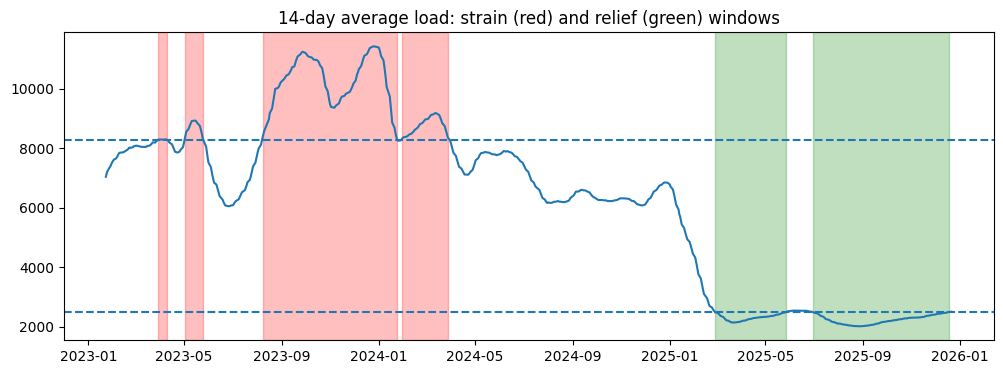

In [6]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(rep.index, rep["load_avg_14d"])
for _, r in list_flag_windows(df, "strain_flag").iterrows():
    ax.axvspan(pd.Timestamp(r["start"]), pd.Timestamp(r["end"]), alpha=0.25, color="red")
for _, r in list_flag_windows(df, "relief_flag").iterrows():
    ax.axvspan(pd.Timestamp(r["start"]), pd.Timestamp(r["end"]), alpha=0.25, color="green")
high, low = compute_thresholds(df)
ax.axhline(high, linestyle="--")
ax.axhline(low, linestyle="--")
ax.set_title("14-day average load: strain (red) and relief (green) windows")